In [1]:
print("Hello! My Data Analyst Internship Project")
print("Project: Superstore Sales Analysis")
print("Tool: Python")

Hello! My Data Analyst Internship Project
Project: Superstore Sales Analysis
Tool: Python


In [2]:
import pandas as pd

print("Pandas imported successfully!")


Pandas imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()


Saving raw_mall_customers.csv to raw_mall_customers (1).csv


In [4]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
import os

files_list = os.listdir('/content')

print("Files available:")
print(files_list)


Files available:
['.config', 'raw_mall_customers (1).csv', 'raw_mall_customers.csv', 'sample_data']


In [7]:
df = pd.read_csv('/content/raw_mall_customers.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Country,Signup Date
0,140,M,68,17,89.0,uk,2023-06-24
1,66,Male,48,133,69.0,Germany,23/01/2023
2,96,M,45,65,26.0,germany,22-03-2022
3,23,Male,55,NaN,17.0,IN,"May 18, 2024"
4,64,Female,67,66,21.0,Germany,07-12-2023


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 220
Number of columns: 7


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              220 non-null    int64  
 1   Gender                  211 non-null    object 
 2   Age                     214 non-null    object 
 3   Annual Income (k$)      210 non-null    object 
 4   Spending Score (1-100)  210 non-null    float64
 5   Country                 214 non-null    object 
 6   Signup Date             213 non-null    object 
dtypes: float64(1), int64(1), object(5)
memory usage: 12.2+ KB


In [12]:
df.describe()

,CustomerID,Spending Score (1-100)
count,220.000000,210.000000
mean,99.363636,53.880952
std,58.693030,40.435075
min,1.000000,1.000000
25%,47.750000,29.250000
50%,98.500000,53.000000
75%,151.250000,75.500000
max,200.000000,480.000000


In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 16


In [13]:
print(df.isnull().sum())

CustomerID                 0
Gender                     9
Age                        6
Annual Income (k$)        10
Spending Score (1-100)    10
Country                    6
Signup Date                7
dtype: int64


In [15]:
import pandas as pd
import os

print(os.listdir('/content'))

['.config', 'superstore_sales.csv', 'raw_mall_customers (1).csv', 'raw_mall_customers.csv', 'sample_data']


In [16]:
df = pd.read_csv('/content/superstore_sales.csv')

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())

   Order Date Region       State         Category Sub-Category    Segment  \
0   11/8/2016  South    Kentucky        Furniture    Bookcases   Consumer   
1   11/8/2016  South    Kentucky        Furniture       Chairs   Consumer   
2   6/12/2016   West  California  Office Supplies       Labels  Corporate   
3  10/11/2015  South     Florida        Furniture       Tables   Consumer   
4  10/11/2015  South     Florida  Office Supplies      Storage   Consumer   

      Sales    Profit  Quantity  
0  261.9600   41.9136         2  
1  731.9400  219.5820         3  
2   14.6200    6.8714         2  
3  957.5775 -383.0310         5  
4   22.3680    2.5164         2  
Dataset shape: (9994, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order Date    9994 non-null   object 
 1   Region        9994 non-null   object 
 2   State         9994 non-nu

In [17]:
df_clean = df.copy()

print("Backup created successfully!")

Backup created successfully!


In [18]:
print("Total duplicate rows:", df_clean.duplicated().sum())

Total duplicate rows: 2


In [19]:
df_clean['Order Date'] = pd.to_datetime(
    df_clean['Order Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

print(df_clean['Order Date'].dtype)

datetime64[ns]


In [20]:
print(df_clean[['Sales', 'Profit', 'Quantity']].dtypes)

Sales       float64
Profit      float64
Quantity      int64
dtype: object


In [21]:
print(df_clean.isnull().sum())

Order Date      0
Region          0
State           0
Category        0
Sub-Category    0
Segment         0
Sales           0
Profit          0
Quantity        0
dtype: int64


In [22]:
print("Negative Sales:", (df_clean['Sales'] < 0).sum())

print("Negative Profit:", (df_clean['Profit'] < 0).sum())

print("Zero Quantity:", (df_clean['Quantity'] == 0).sum())

Negative Sales: 0
Negative Profit: 1871
Zero Quantity: 0


In [23]:
total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
total_quantity = df_clean['Quantity'].sum()
average_sales = df_clean['Sales'].mean()

print("TOTAL SALES:", round(total_sales, 2))
print("TOTAL PROFIT:", round(total_profit, 2))
print("TOTAL QUANTITY:", total_quantity)
print("AVERAGE SALES:", round(average_sales, 2))

TOTAL SALES: 2297200.86
TOTAL PROFIT: 286397.02
TOTAL QUANTITY: 37873
AVERAGE SALES: 229.86


In [24]:
region_sales = df_clean.groupby('Region')['Sales'].sum().sort_values(ascending=False)

print(region_sales)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [25]:
category_analysis = df_clean.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

print(category_analysis)

                       Sales       Profit  Quantity
Category                                           
Furniture        741999.7953   18451.2728      8028
Office Supplies  719047.0320  122490.8008     22906
Technology       836154.0330  145454.9481      6939


In [26]:
segment_analysis = df_clean.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

print(segment_analysis)

                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


In [27]:
subcategory_profit = df_clean.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False)

print(subcategory_profit)

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


In [28]:
df_clean['Month'] = df_clean['Order Date'].dt.to_period('M')

monthly_sales = df_clean.groupby('Month')['Sales'].sum()

print(monthly_sales)

Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160
2017-

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


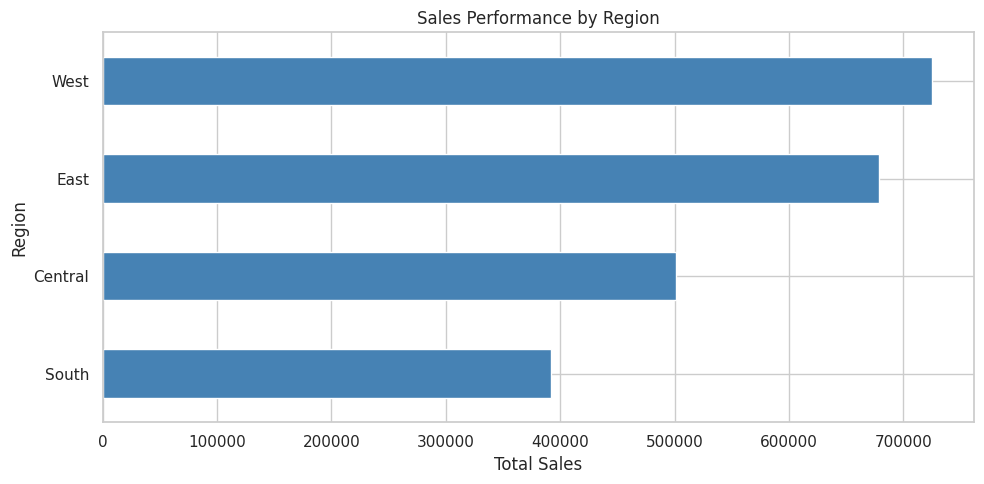

In [30]:
plt.figure(figsize=(10, 5))

region_sales.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Sales Performance by Region')
plt.xlabel('Total Sales')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

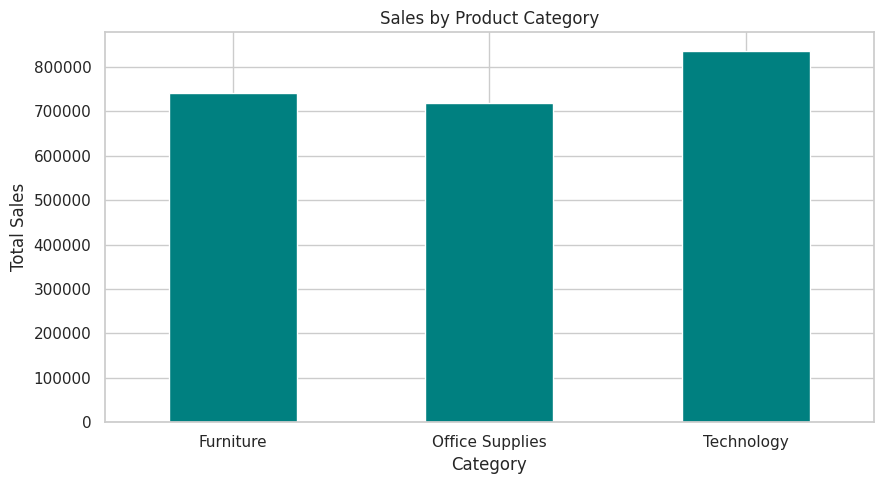

In [31]:
plt.figure(figsize=(9, 5))

category_analysis['Sales'].plot(
    kind='bar',
    color='teal'
)

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

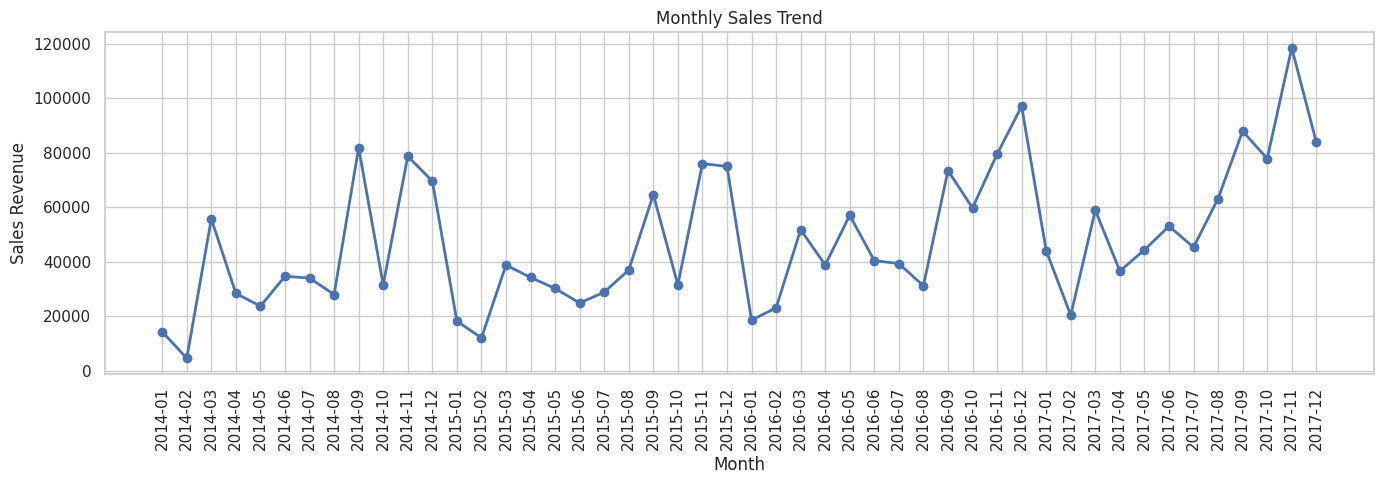

In [32]:
plt.figure(figsize=(14, 5))

monthly_sales.index = monthly_sales.index.astype(str)

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Revenue')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

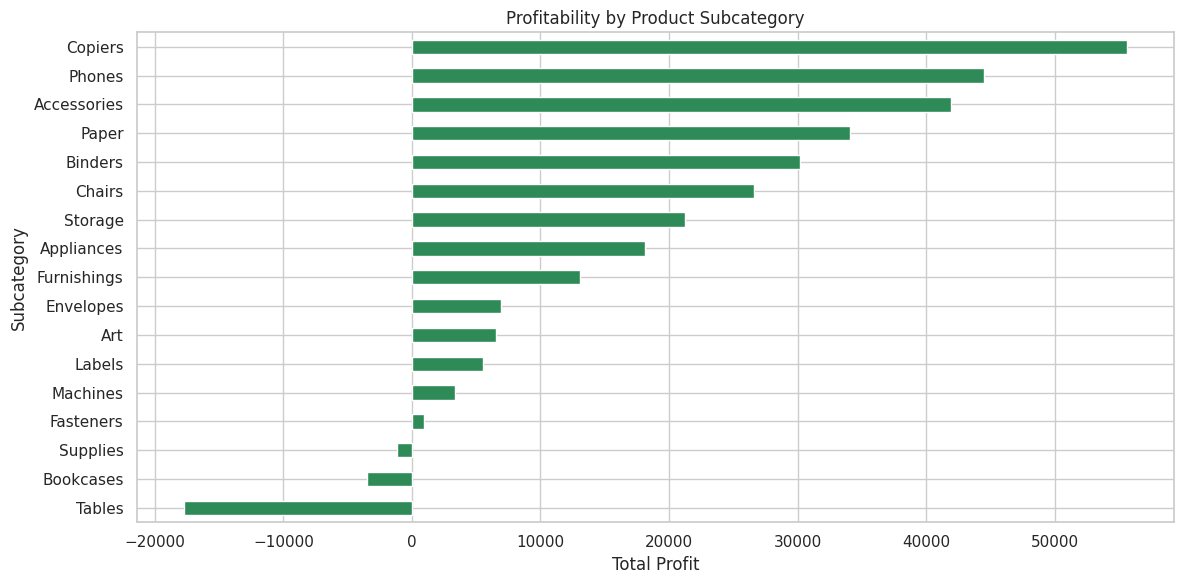

In [33]:
plt.figure(figsize=(12, 6))

subcategory_profit.sort_values().plot(
    kind='barh',
    color='seagreen'
)

plt.title('Profitability by Product Subcategory')
plt.xlabel('Total Profit')
plt.ylabel('Subcategory')

plt.tight_layout()
plt.show()

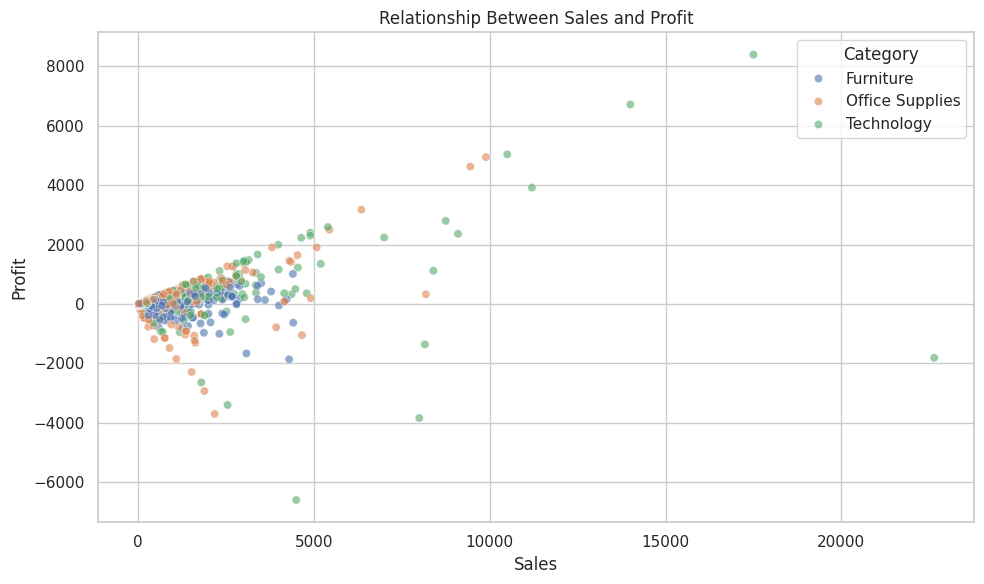

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='Sales',
    y='Profit',
    hue='Category',
    alpha=0.6
)

plt.title('Relationship Between Sales and Profit')
plt.xlabel('Sales')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

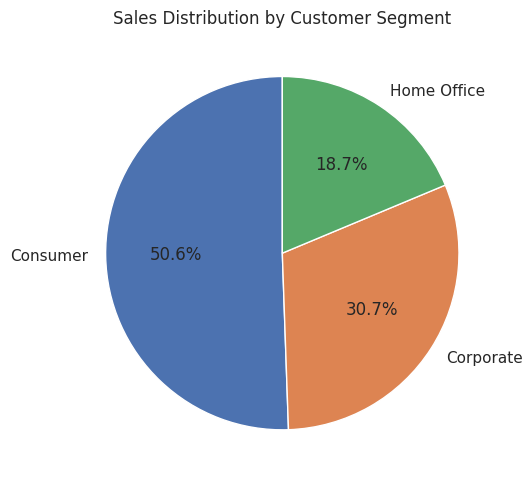

In [35]:
plt.figure(figsize=(8, 5))

segment_analysis['Sales'].plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales Distribution by Customer Segment')
plt.ylabel('')

plt.tight_layout()
plt.show()


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

print("Dashboard setup successful!")

Dashboard setup successful!


In [37]:
total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
total_quantity = df_clean['Quantity'].sum()
average_order_sales = df_clean['Sales'].mean()

print("SUPERSTORE BUSINESS DASHBOARD")
print("-----------------------------")
print("Total Sales: $", round(total_sales, 2))
print("Total Profit: $", round(total_profit, 2))
print("Total Quantity:", total_quantity)
print("Average Sales: $", round(average_order_sales, 2))

SUPERSTORE BUSINESS DASHBOARD
-----------------------------
Total Sales: $ 2297200.86
Total Profit: $ 286397.02
Total Quantity: 37873
Average Sales: $ 229.86


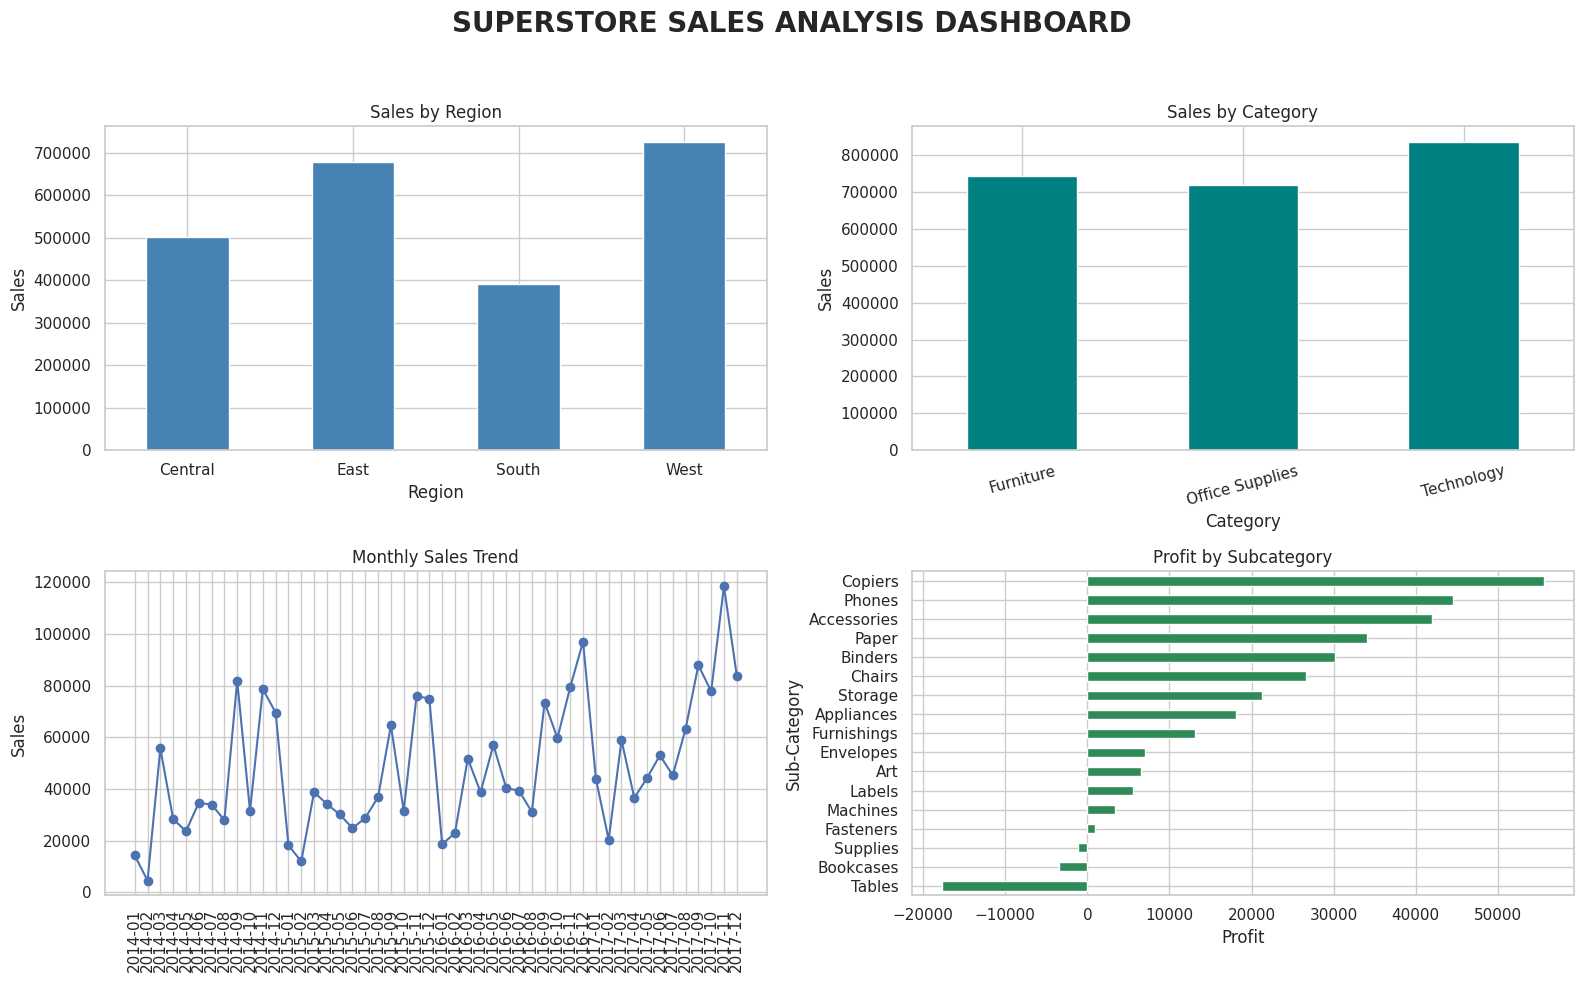

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    'SUPERSTORE SALES ANALYSIS DASHBOARD',
    fontsize=20,
    fontweight='bold'
)

# Chart 1: Regional Sales
region_sales = df_clean.groupby('Region')['Sales'].sum()

region_sales.plot(
    kind='bar',
    ax=axes[0, 0],
    color='steelblue'
)

axes[0, 0].set_title('Sales by Region')
axes[0, 0].set_ylabel('Sales')
axes[0, 0].tick_params(axis='x', rotation=0)

# Chart 2: Category Sales
category_sales = df_clean.groupby('Category')['Sales'].sum()

category_sales.plot(
    kind='bar',
    ax=axes[0, 1],
    color='teal'
)

axes[0, 1].set_title('Sales by Category')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=15)

# Chart 3: Monthly Sales
monthly = df_clean.groupby(
    df_clean['Order Date'].dt.to_period('M')
)['Sales'].sum()

axes[1, 0].plot(
    monthly.index.astype(str),
    monthly.values,
    marker='o'
)

axes[1, 0].set_title('Monthly Sales Trend')
axes[1, 0].set_ylabel('Sales')
axes[1, 0].tick_params(axis='x', rotation=90)

# Chart 4: Subcategory Profit
subcategory = df_clean.groupby(
    'Sub-Category'
)['Profit'].sum().sort_values()

subcategory.plot(
    kind='barh',
    ax=axes[1, 1],
    color='seagreen'
)

axes[1, 1].set_title('Profit by Subcategory')
axes[1, 1].set_xlabel('Profit')

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    'Superstore_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [39]:
from google.colab import files

files.download('Superstore_Dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
region_sales = df_clean.groupby('Region')['Sales'].sum()

best_region = region_sales.idxmax()
best_region_sales = region_sales.max()

print("BEST PERFORMING REGION:", best_region)
print("TOTAL SALES:", round(best_region_sales, 2))

BEST PERFORMING REGION: West
TOTAL SALES: 725457.82


In [41]:
category_sales = df_clean.groupby('Category')['Sales'].sum()

best_category = category_sales.idxmax()

print("TOP PRODUCT CATEGORY:", best_category)
print("CATEGORY SALES:", round(category_sales.max(), 2))

TOP PRODUCT CATEGORY: Technology
CATEGORY SALES: 836154.03


In [43]:
subcategory_profit = df_clean.groupby('Sub-Category')['Profit'].sum()

most_profitable = subcategory_profit.idxmax()
least_profitable = subcategory_profit.idxmin()

print("MOST PROFITABLE:", most_profitable)
print("PROFIT:", round(subcategory_profit.max(), 2))

print("LOWEST PROFIT:", least_profitable)
print("PROFIT:", round(subcategory_profit.min(), 2))

MOST PROFITABLE: Copiers
PROFIT: 55617.82
LOWEST PROFIT: Tables
PROFIT: -17725.48


In [44]:
segment_sales = df_clean.groupby('Segment')['Sales'].sum()

for segment, sales in segment_sales.items():
    print(segment, "Sales:", round(sales, 2))

print("TOP CUSTOMER SEGMENT:", segment_sales.idxmax())

Consumer Sales: 1161401.34
Corporate Sales: 706146.37
Home Office Sales: 429653.15
TOP CUSTOMER SEGMENT: Consumer


In [45]:
monthly_sales = df_clean.groupby(
    df_clean['Order Date'].dt.to_period('M')
)['Sales'].sum()

best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print("BEST SALES MONTH:", best_month)
print("BEST MONTH SALES:", round(monthly_sales.max(), 2))

print("LOWEST SALES MONTH:", worst_month)
print("LOWEST MONTH SALES:", round(monthly_sales.min(), 2))

BEST SALES MONTH: 2017-11
BEST MONTH SALES: 118447.82
LOWEST SALES MONTH: 2014-02
LOWEST MONTH SALES: 4519.89


In [46]:
total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()

profit_margin = (total_profit / total_sales) * 100

print("OVERALL PROFIT MARGIN:", round(profit_margin, 2), "%")

OVERALL PROFIT MARGIN: 12.47 %


In [47]:
print("=" * 55)
print("SUPERSTORE SALES ANALYSIS - BUSINESS INSIGHTS")
print("=" * 55)

print(f"""
1. REGIONAL PERFORMANCE
The highest revenue-generating region is {best_region}.

2. PRODUCT PERFORMANCE
The highest revenue-generating category is {best_category}.

3. PROFITABILITY
The most profitable subcategory is {most_profitable}.
The lowest-profit subcategory is {least_profitable}.

4. CUSTOMER ANALYSIS
The leading customer segment is {segment_sales.idxmax()}.

5. SALES TRENDS
The highest sales occurred in {best_month}.
The lowest sales occurred in {worst_month}.

6. BUSINESS PROFITABILITY
The overall profit margin is {profit_margin:.2f}%.
""")

print("=" * 55)

SUPERSTORE SALES ANALYSIS - BUSINESS INSIGHTS

1. REGIONAL PERFORMANCE
The highest revenue-generating region is West.

2. PRODUCT PERFORMANCE
The highest revenue-generating category is Technology.

3. PROFITABILITY
The most profitable subcategory is Copiers.
The lowest-profit subcategory is Tables.

4. CUSTOMER ANALYSIS
The leading customer segment is Consumer.

5. SALES TRENDS
The highest sales occurred in 2017-11.
The lowest sales occurred in 2014-02.

6. BUSINESS PROFITABILITY
The overall profit margin is 12.47%.



In [48]:
insights = f"""
SUPERSTORE SALES ANALYSIS
DATA ANALYST INTERNSHIP - TASK 2

PROJECT OVERVIEW
This project analyzes Superstore sales data
using Python, Pandas, Matplotlib and Seaborn.

DATASET OVERVIEW
Total Records: {len(df_clean)}
Total Columns: {len(df_clean.columns)}

BUSINESS PERFORMANCE
Total Sales: ${total_sales:,.2f}
Total Profit: ${total_profit:,.2f}
Total Quantity: {total_quantity}
Profit Margin: {profit_margin:.2f}%

KEY BUSINESS FINDINGS

1. Top Region: {best_region}
2. Top Revenue Category: {best_category}
3. Most Profitable Subcategory: {most_profitable}
4. Lowest Profit Subcategory: {least_profitable}
5. Leading Customer Segment: {segment_sales.idxmax()}
6. Best Sales Month: {best_month}
7. Lowest Sales Month: {worst_month}

BUSINESS RECOMMENDATIONS

1. Study successful strategies in the West region.
2. Evaluate opportunities in Technology products.
3. Review pricing and costs for Tables.
4. Strengthen Consumer customer retention.
5. Plan inventory around high-sales periods.

CONCLUSION
The analysis provides insights into sales,
profitability, regional performance and customer
segments to support better business decisions.
"""

with open("Business_Insights_Report.txt", "w") as f:
    f.write(insights)

print("Business insights report created successfully!")

Business insights report created successfully!


In [49]:
from google.colab import files

files.download("Business_Insights_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.4 MB/s  0:00:00


In [51]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, Table, TableStyle, PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4
import os

# Create PDF
pdf_file = "Superstore_Sales_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    'TitleCustom',
    parent=styles['Title'],
    fontSize=22,
    textColor=colors.HexColor('#17365D'),
    alignment=TA_CENTER,
    spaceAfter=20
)

heading_style = ParagraphStyle(
    'HeadingCustom',
    parent=styles['Heading2'],
    textColor=colors.HexColor('#17365D'),
    spaceBefore=15,
    spaceAfter=8
)

story = []

# Title
story.append(Paragraph(
    "SUPERSTORE SALES ANALYSIS",
    title_style
))

story.append(Paragraph(
    "DATA ANALYST INTERNSHIP - TASK 2",
    styles['Heading3']
))

story.append(Spacer(1, 15))

# Introduction
story.append(Paragraph(
    "1. PROJECT INTRODUCTION",
    heading_style
))

story.append(Paragraph(
    "This project analyzes Superstore sales data using "
    "Python, Pandas, Matplotlib and Seaborn. "
    "The objective is to identify business trends, "
    "sales performance and profitability insights.",
    styles['BodyText']
))

# Dataset
story.append(Paragraph(
    "2. DATASET OVERVIEW",
    heading_style
))

dataset_data = [
    ["Metric", "Value"],
    ["Total Records", f"{len(df_clean):,}"],
    ["Total Columns", f"{len(df_clean.columns)}"],
    ["Total Sales", f"${total_sales:,.2f}"],
    ["Total Profit", f"${total_profit:,.2f}"],
    ["Total Quantity", f"{total_quantity:,}"],
    ["Profit Margin", f"{profit_margin:.2f}%"]
]

table = Table(dataset_data, colWidths=[220, 220])

table.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#17365D')),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.grey),
    ('PADDING', (0, 0), (-1, -1), 8),
]))

story.append(table)

# Dashboard
story.append(Paragraph(
    "3. SALES DASHBOARD",
    heading_style
))

if os.path.exists("Superstore_Dashboard.png"):
    dashboard = Image(
        "Superstore_Dashboard.png",
        width=7.1*inch,
        height=4.5*inch
    )
    story.append(dashboard)
else:
    story.append(Paragraph(
        "Dashboard image was not uploaded.",
        styles['BodyText']
    ))

# Business Insights
story.append(PageBreak())

story.append(Paragraph(
    "4. KEY BUSINESS INSIGHTS",
    heading_style
))

insights = [
    f"Highest revenue region: {best_region}",
    f"Highest revenue category: {best_category}",
    f"Most profitable subcategory: {most_profitable}",
    f"Lowest-profit subcategory: {least_profitable}",
    f"Leading customer segment: {segment_sales.idxmax()}",
    f"Best sales month: {best_month}",
    f"Lowest sales month: {worst_month}",
    f"Overall profit margin: {profit_margin:.2f}%"
]

for item in insights:
    story.append(Paragraph(
        "• " + item,
        styles['BodyText']
    ))
    story.append(Spacer(1, 7))

# Recommendations
story.append(Paragraph(
    "5. BUSINESS RECOMMENDATIONS",
    heading_style
))

recommendations = [
    "Study successful strategies in the West region.",
    "Evaluate opportunities in Technology products.",
    "Review pricing and costs associated with Tables.",
    "Strengthen Consumer customer retention.",
    "Plan inventory around high-sales periods."
]

for item in recommendations:
    story.append(Paragraph(
        "• " + item,
        styles['BodyText']
    ))
    story.append(Spacer(1, 7))

# Conclusion
story.append(Paragraph(
    "6. CONCLUSION",
    heading_style
))

story.append(Paragraph(
    "The analysis provides valuable insights into "
    "regional performance, product categories, "
    "customer segments and profitability. "
    "These findings can support informed business "
    "decisions and improve sales performance.",
    styles['BodyText']
))

# Build PDF
doc.build(story)

print("PDF report created successfully!")
print("File:", pdf_file)

PDF report created successfully!
File: Superstore_Sales_Analysis_Report.pdf


In [52]:
from google.colab import files

files.download("Superstore_Sales_Analysis_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>